# Unidad 10 — NumPy y Pandas: Introducción

**Programación Orientada a Objetos — ISTEA**

NumPy es la base del ecosistema científico de Python. Pandas construye sobre NumPy
para ofrecer estructuras tabulares de alto nivel. Son imprescindibles para análisis de datos.

**Temas que practico en esta unidad:**
- Crear y manipular arrays de NumPy
- Entender shape, ndim, dtype, size y reshape
- Aplicar slicing y boolean indexing en arrays
- Aprovechar vectorización y broadcasting
- Crear Series y DataFrames de Pandas
- Usar loc/iloc para acceso y filtrado
- Realizar operaciones con columnas

*Consignas de la cátedra. Resoluciones desarrolladas durante la cursada.*

## Ejercicios

### 🟢 Ejercicio 1 — Creación y propiedades de arrays
Crear arrays con zeros, ones, arange y linspace. Verificar shape y dtype.


In [1]:
# 🎯 EJERCICIO 1: Crear y explorar arrays
import numpy as np

# 1. Crear los 4 arrays solicitados
arr_zeros = np.zeros((4, 4))
arr_ones = np.ones((2, 5))
arr_arange = np.arange(0, 51, 5) # 51 para incluir el 50
arr_linspace = np.linspace(0, 3.14, 7)

# 2. Guardarlos en un diccionario para iterar y mostrar sus propiedades de forma limpia
arrays = {
    "Zeros (4x4)": arr_zeros,
    "Ones (2x5)": arr_ones,
    "Arange (0 a 50)": arr_arange,
    "Linspace (0 a 3.14)": arr_linspace
}

for nombre, arr in arrays.items():
    print(f"--- {nombre} ---")
    print(f"Contenido:\n{arr}")
    print(f"Shape: {arr.shape}")
    print(f"Dtype: {arr.dtype}\n")

--- Zeros (4x4) ---
Contenido:
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]
Shape: (4, 4)
Dtype: float64

--- Ones (2x5) ---
Contenido:
[[1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]]
Shape: (2, 5)
Dtype: float64

--- Arange (0 a 50) ---
Contenido:
[ 0  5 10 15 20 25 30 35 40 45 50]
Shape: (11,)
Dtype: int64

--- Linspace (0 a 3.14) ---
Contenido:
[0.         0.52333333 1.04666667 1.57       2.09333333 2.61666667
 3.14      ]
Shape: (7,)
Dtype: float64



### 🟡 Ejercicio 2 — Slicing y boolean indexing en matriz
Dada una matriz 4x4, extraer la diagonal, el triángulo superior, y elementos > media.


In [2]:
# 🎯 EJERCICIO 2: Slicing avanzado
import numpy as np
np.random.seed(27)
matriz = np.random.randint(1, 50, (4, 4))
print(f"Matriz:\n{matriz}\n")

# Extracción de diagonal sin metodo:
diagonal_lista = []
for fila in range(matriz.shape[0]):
    for col in range(matriz.shape[1]):
        if fila == col:
            diagonal_lista.append(int(matriz[fila, col]))
print(f"Diagonal (lista): {diagonal_lista}")

# 1. Diagonal con np.diag()
diagonal = np.diag(matriz)
print(f"1. Diagonal:\n{diagonal}\n")

# 2. Triángulo superior con np.triu()
triangulo_sup = np.triu(matriz)
print(f"2. Triángulo superior:\n{triangulo_sup}\n")

# Triangulo inferior:
triangulo_inf = np.tril(matriz)
print(f"Triángulo inferior:\n{triangulo_inf}\n")

# 3. Elementos mayores que la media
media = matriz.mean()
mayores_que_media = matriz[matriz > media]
print(f"Media de la matriz: {media:.2f}")
print(f"3. Elementos mayores que la media:\n{mayores_que_media}")

Matriz:
[[20  9 32 49]
 [38 25 26 14]
 [ 3 43 34 47]
 [11  5 32 20]]

Diagonal (lista): [20, 25, 34, 20]
1. Diagonal:
[20 25 34 20]

2. Triángulo superior:
[[20  9 32 49]
 [ 0 25 26 14]
 [ 0  0 34 47]
 [ 0  0  0 20]]

Triángulo inferior:
[[20  0  0  0]
 [38 25  0  0]
 [ 3 43 34  0]
 [11  5 32 20]]

Media de la matriz: 25.50
3. Elementos mayores que la media:
[32 49 38 26 43 34 47 32]


### 🟡 Ejercicio 3 — Broadcasting
Sumar un vector fila a cada fila de una matriz sin bucles explícitos.


In [3]:
# 🎯 EJERCICIO 3: Broadcasting
import numpy as np

matriz = np.array([[1, 2, 3], [4, 5, 6], [7, 8, 9]])
ajuste = np.array([10, 0, -5])  # Vector fila

# NumPy aplica broadcasting automáticamente al sumar un vector de shape (3,)
# a una matriz de shape (3, 3) a lo largo de sus filas.
resultado = matriz + ajuste

print("Resultado obtenido:")
print(resultado)

Resultado obtenido:
[[11  2 -2]
 [14  5  1]
 [17  8  4]]


### 🟡 Ejercicio 4 — DataFrame: crear, filtrar, ordenar
Crear un DataFrame de ventas, agregar columna calculada, filtrar y ordenar.


In [4]:
ventas_data = {
    "vendedor": ["Ana", "Beto", "Clara", "Diego", "Elena"],
    "region": ["Norte", "Sur", "Norte", "Este", "Sur"],
    "q1": [120000, 95000, 145000, 88000, 132000],
    "q2": [135000, 102000, 138000, 91000, 145000],
}

# Transformación de diccionario de listas a lista de diccionarios
lista_ventas = [
    {
        "vendedor": v,
        "region": r,
        "q1": q1,
        "q2": q2
    }
    for v, r, q1, q2 in zip(
        ventas_data["vendedor"],
        ventas_data["region"],
        ventas_data["q1"],
        ventas_data["q2"]
    )
]

# Mostrar el resultado
import pprint
pprint.pprint(lista_ventas)

[{'q1': 120000, 'q2': 135000, 'region': 'Norte', 'vendedor': 'Ana'},
 {'q1': 95000, 'q2': 102000, 'region': 'Sur', 'vendedor': 'Beto'},
 {'q1': 145000, 'q2': 138000, 'region': 'Norte', 'vendedor': 'Clara'},
 {'q1': 88000, 'q2': 91000, 'region': 'Este', 'vendedor': 'Diego'},
 {'q1': 132000, 'q2': 145000, 'region': 'Sur', 'vendedor': 'Elena'}]


In [5]:
# 🎯 EJERCICIO 4: DataFrame básico
import pandas as pd

ventas_data = {
    "vendedor": ["Ana", "Beto", "Clara", "Diego", "Elena"],
    "region": ["Norte", "Sur", "Norte", "Este", "Sur"],
    "q1": [120000, 95000, 145000, 88000, 132000],
    "q2": [135000, 102000, 138000, 91000, 145000],
}

ventas_data2 = [{'q1': 120000, 'q2': 135000, 'region': 'Norte', 'vendedor': 'Ana'},
 {'q1': 95000, 'q2': 102000, 'region': 'Sur', 'vendedor': 'Beto'},
 {'q1': 145000, 'q2': 138000, 'region': 'Norte', 'vendedor': 'Clara'},
 {'q1': 88000, 'q2': 91000, 'region': 'Este', 'vendedor': 'Diego'},
 {'q1': 132000, 'q2': 145000, 'region': 'Sur', 'vendedor': 'Elena'}]

df = pd.DataFrame(ventas_data)
display(df)

print()

df2 = pd.DataFrame(ventas_data2)
display(df2)

print()

# 1. Agregar columna "total" = q1 + q2
df["total"] = df["q1"] + df["q2"]
display(df)
# 2. Filtrar vendedores con total > 250000
print()
print("Vendedores con total > 250000:")
mascara = df["total"] > 250000
display(mascara)
display(df[mascara])
print()
# 3. Ordenar por total descendente
print("Ordenado por total descendente:")
display(df.sort_values(by="total", ascending=False))

,vendedor,region,q1,q2
0,Ana,Norte,120000,135000
1,Beto,Sur,95000,102000
2,Clara,Norte,145000,138000
3,Diego,Este,88000,91000
4,Elena,Sur,132000,145000


,q1,q2,region,vendedor
0,120000,135000,Norte,Ana
1,95000,102000,Sur,Beto
2,145000,138000,Norte,Clara
3,88000,91000,Este,Diego
4,132000,145000,Sur,Elena


,vendedor,region,q1,q2,total
0,Ana,Norte,120000,135000,255000
1,Beto,Sur,95000,102000,197000
2,Clara,Norte,145000,138000,283000
3,Diego,Este,88000,91000,179000
4,Elena,Sur,132000,145000,277000



Vendedores con total > 250000:


0     True
1    False
2     True
3    False
4     True
Name: total, dtype: bool

,vendedor,region,q1,q2,total
0,Ana,Norte,120000,135000,255000
2,Clara,Norte,145000,138000,283000
4,Elena,Sur,132000,145000,277000



Ordenado por total descendente:


,vendedor,region,q1,q2,total
2,Clara,Norte,145000,138000,283000
4,Elena,Sur,132000,145000,277000
0,Ana,Norte,120000,135000,255000
1,Beto,Sur,95000,102000,197000
3,Diego,Este,88000,91000,179000


### 🔴 Ejercicio 5 — Rolling mean en Series de temperaturas
Calcular la media móvil de 7 días en una serie de temperaturas diarias.


In [6]:
# 🎯 EJERCICIO 5: Rolling mean de temperaturas
import pandas as pd
import numpy as np

np.random.seed(42)
temperaturas = pd.Series(
    np.random.uniform(15, 35, 30).round(1),
    name="Temp diaria (°C)"
)

display(temperaturas)

# Calcular la media móvil de 7 días
# (Los primeros 6 días serán NaN porque no completan la ventana de 7)
media_movil = temperaturas.rolling(window=7, min_periods=1).mean()

# Combinar la serie original y la media móvil para comparar el resultado
df_temp = pd.DataFrame({
    "Temp Original": temperaturas,
    "Media Móvil (7d)": media_movil.round(2)
})

print("Últimos 7 días de la serie:")
display(df_temp)

0     22.5
1     34.0
2     29.6
3     27.0
4     18.1
5     18.1
6     16.2
7     32.3
8     27.0
9     29.2
10    15.4
11    34.4
12    31.6
13    19.2
14    18.6
15    18.7
16    21.1
17    25.5
18    23.6
19    20.8
20    27.2
21    17.8
22    20.8
23    22.3
24    24.1
25    30.7
26    19.0
27    25.3
28    26.8
29    15.9
Name: Temp diaria (°C), dtype: float64

Últimos 7 días de la serie:


,Temp Original,Media Móvil (7d)
0,22.5,22.50
1,34.0,28.25
2,29.6,28.70
3,27.0,28.28
4,18.1,26.24
5,18.1,24.88
6,16.2,23.64
7,32.3,25.04
8,27.0,24.04
9,29.2,23.99


## Desafío extra 🔴

Implementar **K-Means clustering** desde cero usando solo NumPy:
- Función `kmeans(datos, k, iteraciones=100)` que retorna centroides y etiquetas
- Generar 200 puntos en 3 clusters sintéticos
- Visualizar con matplotlib si disponible
- Calcular inercia (suma de distancias cuadradas a centroides) por iteración


Inercia final de cada corrida: [96.1, 96.1, 96.1, 738.0, 96.1, 96.1, 96.1, 96.1, 737.4, 96.1]

Mejor corrida: convergió en 2 iteraciones
Centroides:
[[2.02 2.1 ]
 [1.92 7.97]
 [5.94 5.95]]
Puntos por cluster: [70 60 70]


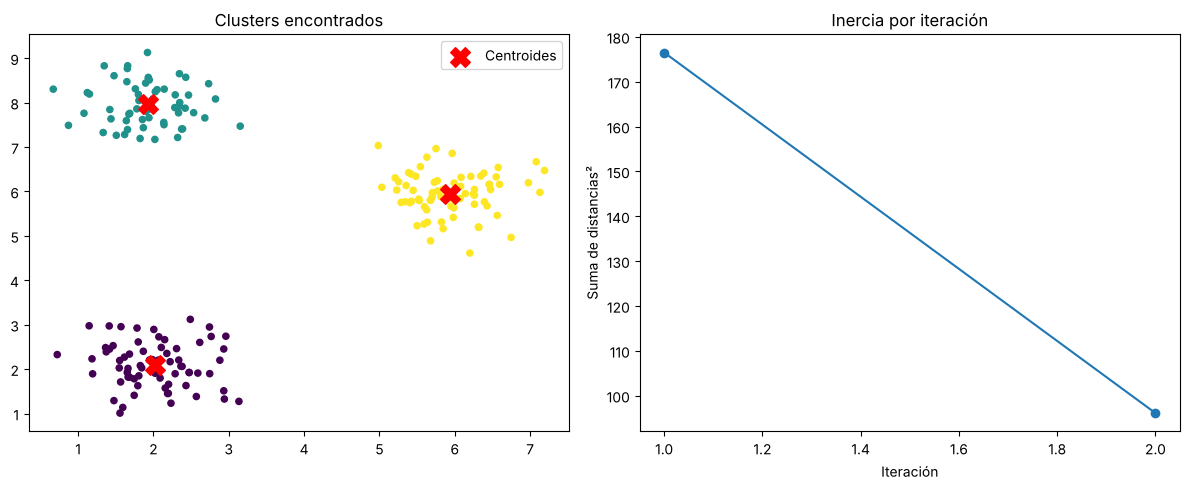

In [7]:
# 🔴 Desafío: K-Means con NumPy puro
import numpy as np
import matplotlib.pyplot as plt

def kmeans(datos, k, iteraciones=100, seed=42):
    np.random.seed(seed)
    # 1. Centroides iniciales: k puntos al azar del dataset
    centroides = datos[np.random.choice(len(datos), k, replace=False)]
    inercias = []
    for _ in range(iteraciones):
        # 2. Distancia de cada punto a cada centroide (broadcasting: (n,1,2) - (1,k,2))
        distancias = np.linalg.norm(datos[:, None, :] - centroides[None, :, :], axis=2)
        etiquetas = distancias.argmin(axis=1)
        inercias.append(float((distancias[np.arange(len(datos)), etiquetas] ** 2).sum()))
        # 3. Nuevo centroide = promedio de los puntos asignados
        nuevos = np.array([datos[etiquetas == j].mean(axis=0) for j in range(k)])
        if np.allclose(nuevos, centroides):   # 4. Si no se mueven más, terminó
            break
        centroides = nuevos
    return centroides, etiquetas, inercias

# Generar datos sintéticos
np.random.seed(0)
cluster1 = np.random.normal([2, 2], 0.5, (70, 2))
cluster2 = np.random.normal([6, 6], 0.5, (70, 2))
cluster3 = np.random.normal([2, 8], 0.5, (60, 2))
datos = np.vstack([cluster1, cluster2, cluster3])

# Con una sola inicialización al azar a veces dos centroides arrancan en el mismo grupo
# y el algoritmo queda trabado en una mala solución. Por eso lo corro 10 veces con
# semillas distintas y me quedo con la de menor inercia final (lo mismo que hace n_init en sklearn).
resultados = [kmeans(datos, k=3, seed=s) for s in range(10)]
print("Inercia final de cada corrida:", [round(r[2][-1], 1) for r in resultados])
centroides, etiquetas, inercias = min(resultados, key=lambda r: r[2][-1])
print(f"\nMejor corrida: convergió en {len(inercias)} iteraciones")
print(f"Centroides:\n{centroides.round(2)}")
print(f"Puntos por cluster: {np.bincount(etiquetas)}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(datos[:, 0], datos[:, 1], c=etiquetas, cmap="viridis", s=20)
axes[0].scatter(centroides[:, 0], centroides[:, 1], c="red", marker="X", s=200, label="Centroides")
axes[0].set_title("Clusters encontrados")
axes[0].legend()
axes[1].plot(range(1, len(inercias) + 1), inercias, "o-")
axes[1].set_title("Inercia por iteración")
axes[1].set_xlabel("Iteración")
axes[1].set_ylabel("Suma de distancias²")
plt.tight_layout()
plt.show()

## Resumen de conceptos

| Concepto | Código | Descripción |
|---|---|---|
| Crear array | `np.array([...])` | Desde lista |
| Zeros/Ones | `np.zeros((m,n))` | Arrays de 0s o 1s |
| Arange | `np.arange(ini, fin, paso)` | Secuencia entera |
| Linspace | `np.linspace(ini, fin, n)` | n puntos uniformes |
| Shape | `arr.shape` | Dimensiones |
| Reshape | `arr.reshape(m, n)` | Cambiar forma |
| Boolean index | `arr[arr > 5]` | Filtrado por condición |
| Broadcasting | `arr + vector` | Op. con formas compatibles |
| Vectorización | `arr * 2` | Op. elemento a elemento |
| Serie Pandas | `pd.Series(data, index)` | Array 1D etiquetado |
| DataFrame | `pd.DataFrame(dict)` | Tabla 2D etiquetada |
| loc / iloc | `df.loc[fila, col]` | Acceso por etiqueta/posición |
| rolling | `s.rolling(n).mean()` | Media móvil |
